# Recurrent Neural Network (LSTM) on Fashion MNIST Dataset

In this lab, we implement a **Long Short-Term Memory (LSTM)** network using TensorFlow / Keras.

#### Deep Learning Concepts from Syllabus:
- **Recurrent Neural Networks (RNN)**: Designed for sequence processing where past states influence future predictions.
- **Vanishing Gradients Problem**: Standard RNNs struggle with long sequences because gradients decay exponentially during backpropagation through time (BPTT).
- **LSTM Architecture**: Uses gating mechanisms (Input gate, Forget gate, Output gate, Cell state) to preserve gradients and learn long-range temporal dependencies.
- **Fashion MNIST Formulation**: Each $28 \times 28$ image is treated as a temporal sequence of 28 time steps, with 28 features per step.

### 1. Importing the necessary modules

In [1]:
import os, sys
# Fix for NVIDIA RTX 50-series (Blackwell CC 12.0) GPU autotuner
os.environ['TF_CUDNN_USE_AUTOTUNE'] = '0'
os.environ['TF_XLA_FLAGS'] = '--tf_xla_auto_jit=0'

cuda_bin = os.path.join(sys.prefix, 'lib', f'python{sys.version_info.major}.{sys.version_info.minor}', 'site-packages', 'nvidia', 'cuda_nvcc', 'bin')
if os.path.exists(cuda_bin):
    os.environ['PATH'] = cuda_bin + os.pathsep + os.environ.get('PATH', '')

import os, sys
# Prioritize virtual environment CUDA 12.9 compiler binaries for RTX 50-series (Blackwell)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

I0000 00:00:1789020505.484226   81889 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1789020505.511279   81889 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1789020506.239612   81889 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


### 2. Loading the Fashion MNIST dataset

In [2]:
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

print(f"x_train shape: {x_train.shape}, y_train shape: {y_train.shape}")
print(f"x_test shape:  {x_test.shape}, y_test shape:  {y_test.shape}")

x_train shape: (60000, 28, 28), y_train shape: (60000,)
x_test shape:  (10000, 28, 28), y_test shape:  (10000,)


### 3. Visualizing Sample Images with Labels

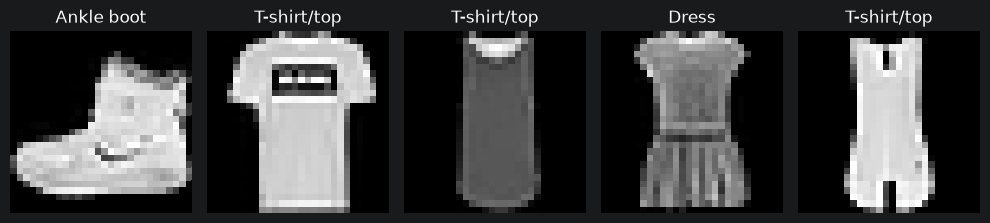

In [3]:
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

plt.figure(figsize=(10, 4))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(class_names[y_train[i]])
    plt.axis('off')
plt.tight_layout()
plt.show()

### 4. Normalizing Pixel Values (0 to 1)

In [4]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

print(f"x_train min: {x_train.min()}, max: {x_train.max()}")

x_train min: 0.0, max: 1.0


### 5. Defining the LSTM Model Architecture

In [5]:
model = Sequential([
    LSTM(128, input_shape=(28, 28)),
    Dropout(0.2),
    Dense(10, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
    jit_compile=False
)

model.summary()

W0000 00:00:1789020507.671606   81889 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
W0000 00:00:1789020507.679663   81889 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1789020507.785398   81889 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5759 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5070 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 12.0a
/home/takrim/Desktop/ICE-M2012/.venv/lib/python3.13/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
 

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 128)            │        80,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 81,674 (319.04 KB)

 Trainable params: 81,674 (319.04 KB)

 Non-trainable params: 0 (0.00 B)

### 6. Training the LSTM Model

In [6]:
# Train for 5 epochs to demonstrate convergence
history = model.fit(
    x_train,
    y_train,
    batch_size=128,
    epochs=5,
    validation_split=0.2,
    verbose=1
)

Epoch 1/5


I0000 00:00:1789020509.595956   82045 cuda_dnn.cc:461] Loaded cuDNN version 92501


375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7405 - loss: 0.7086 - val_accuracy: 0.8182 - val_loss: 0.4910
Epoch 2/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8238 - loss: 0.4790 - val_accuracy: 0.8378 - val_loss: 0.4446
Epoch 3/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8423 - loss: 0.4286 - val_accuracy: 0.8479 - val_loss: 0.4109
Epoch 4/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8535 - loss: 0.3960 - val_accuracy: 0.8601 - val_loss: 0.3844
Epoch 5/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8614 - loss: 0.3732 - val_accuracy: 0.8726 - val_loss: 0.3546


### 7. Visualizing Training and Validation Curves

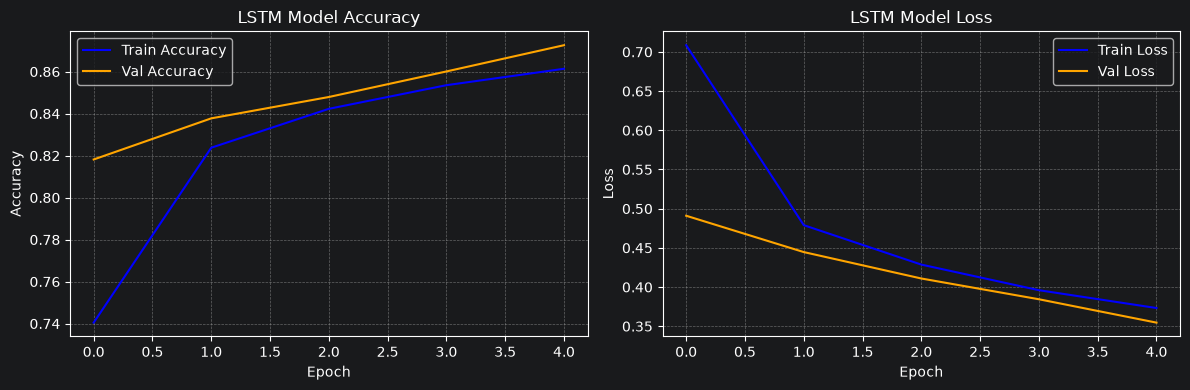

In [7]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy', color='blue')
plt.plot(history.history['val_accuracy'], label='Val Accuracy', color='orange')
plt.title('LSTM Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss', color='blue')
plt.plot(history.history['val_loss'], label='Val Loss', color='orange')
plt.title('LSTM Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### 8. Evaluating the Model on Test Data

In [8]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
print(f"Test Loss:     {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Loss:     0.3718
Test Accuracy: 86.15%


### 9. Predicting and Generating Confusion Matrix & Classification Report

In [9]:
y_pred_probs = model.predict(x_test)
y_pred = np.argmax(y_pred_probs, axis=1)

cm = confusion_matrix(y_test, y_pred)

print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=class_names))

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
Classification Report:
              precision    recall  f1-score   support

 T-shirt/top       0.83      0.78      0.80      1000
     Trouser       0.99      0.94      0.97      1000
    Pullover       0.79      0.71      0.75      1000
       Dress       0.85      0.89      0.87      1000
        Coat       0.75      0.81      0.78      1000
      Sandal       0.98      0.94      0.96      1000
       Shirt       0.64      0.68      0.66      1000
     Sneaker       0.92      0.94      0.93      1000
         Bag       0.97      0.97      0.97      1000
  Ankle boot       0.94      0.95      0.94      1000

    accuracy                           0.86     10000
   macro avg       0.86      0.86      0.86     10000
weighted avg       0.86      0.86      0.86     10000



### 10. Visualizing the Confusion Matrix Heatmap

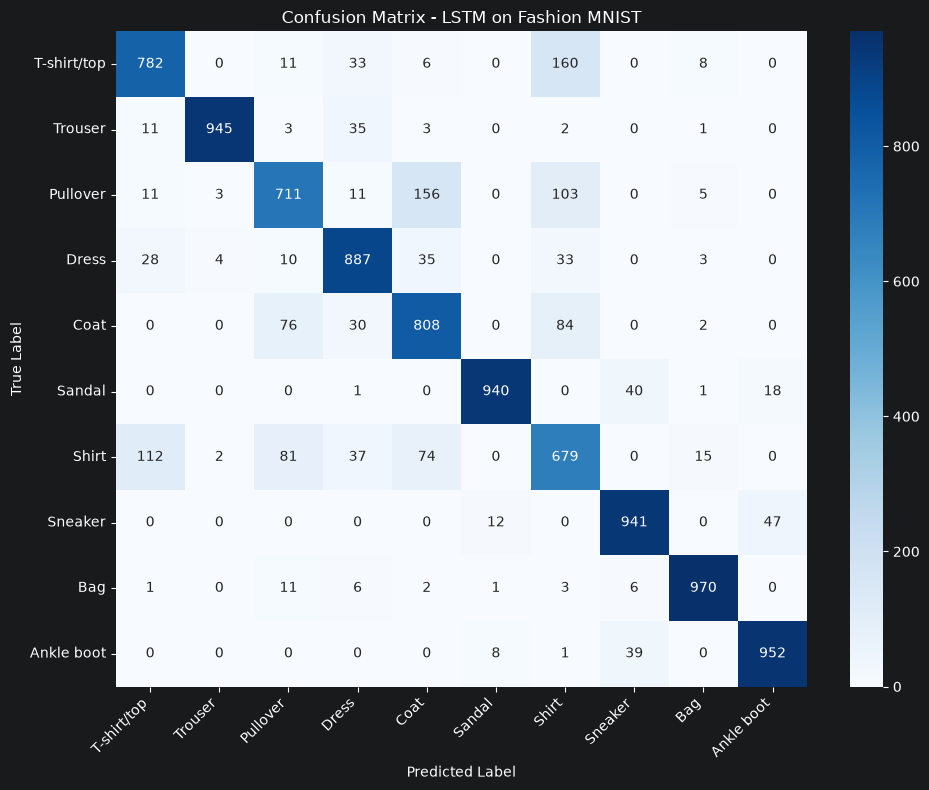

In [10]:
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - LSTM on Fashion MNIST')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()